# Data cleaning 3 – Experiment Roster (`df_final_experiment_clients`)

**Project:** Vanguard A/B Test ·  **Data cleaning 3 - Experiment Roster ** prepared by Juliana

This dataset tells us which clients took part in the experiment and in which group:
- **Control**: old online process
- **Test**: new redesigned interface

**Goal:** a clean list of `client_id` + `variation` (Test / Control) that the team can merge with the Client Profiles (Lervin) and the Digital Footprints (Raquel).

### Cleaning checklist
1. Load the data and take a first look
2. Standardise column names
3. Check data types
4. Duplicates (rows and `client_id`)
5. Validity of `client_id`
6. Values of `variation` (labels, typos, extra spaces)
7. Missing values → clients not in the experiment
8. Clients in more than one group
9. Group sizes and balance (Test vs Control)
10. Cross-check with the other datasets
11. Apply the reusable cleaning function (`src/cleaning.py`) and save
12. Summary of decisions

## 0. Setup

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# make the project's src/ folder importable (the notebook lives in notebooks/)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT))

from src.cleaning import DATA_URL, EXPERIMENT_FILE, load_raw, clean_experiment_clients

RAW_DIR = PROJECT_ROOT / "data" / "raw"
CLEAN_DIR = PROJECT_ROOT / "data" / "clean"
FIG_DIR = PROJECT_ROOT / "figures"
for d in (RAW_DIR, CLEAN_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 1. Load the data and take a first look

In [2]:
df_raw = load_raw(EXPERIMENT_FILE)

# keep an untouched copy of the original file in data/raw
df_raw.to_csv(RAW_DIR / EXPERIMENT_FILE, index=False)

df = df_raw.copy()
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 70,609 rows x 2 columns


,client_id,Variation
0,9988021,Test
1,8320017,Test
2,4033851,Control
3,1982004,Test
4,9294070,Control


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70609 entries, 0 to 70608
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   client_id  70609 non-null  int64
 1   Variation  50500 non-null  str  
dtypes: int64(1), str(1)
memory usage: 1.1 MB


In [4]:
df.sample(5, random_state=42)

,client_id,Variation
61666,4880891,NaN
39329,7826607,Control
28837,5510017,Control
16814,7297910,Test
70404,6801251,NaN


## 2. Standardise column names
The other datasets use lowercase names (`client_id`, `clnt_age`, …), but here we have `Variation`. Using lowercase everywhere avoids errors when we merge.

In [5]:
print("Before:", list(df.columns))
df.columns = df.columns.str.strip().str.lower()
print("After: ", list(df.columns))

Before: ['client_id', 'Variation']
After:  ['client_id', 'variation']


## 3. Data types

In [6]:
df.dtypes

client_id    int64
variation      str
dtype: object

`client_id` should be an integer and `variation` text. If `client_id` shows up as `float64`, it means it has missing values (which we check in step 5).

## 4. Duplicates

In [7]:
n_dup_rows = df.duplicated().sum()
n_dup_ids = df["client_id"].duplicated().sum()
print(f"Fully duplicated rows : {n_dup_rows:,}")
print(f"Duplicated client_id  : {n_dup_ids:,}")

Fully duplicated rows : 0
Duplicated client_id  : 0


In [8]:
# if there are any duplicates, show them
df[df["client_id"].duplicated(keep=False)].sort_values("client_id").head(10)

,client_id,variation


## 5. Validity of `client_id`

In [9]:
print("Missing client_id :", df["client_id"].isna().sum())
print("Non-positive IDs  :", (df["client_id"] <= 0).sum())
print("Is integer type   :", pd.api.types.is_integer_dtype(df["client_id"]))
df["client_id"].describe()

Missing client_id : 0
Non-positive IDs  : 0
Is integer type   : True


count    7.060900e+04
mean     5.004992e+06
std      2.877278e+06
min      1.690000e+02
25%      2.519329e+06
50%      5.016978e+06
75%      7.483085e+06
max      9.999839e+06
Name: client_id, dtype: float64

## 6. Values of `variation`

In [10]:
# dropna=False also shows the missing values
df["variation"].value_counts(dropna=False)

variation
Test       26968
Control    23532
NaN        20109
Name: count, dtype: int64

In [11]:
# look for hidden problems: extra spaces or different upper/lower case
labels = df["variation"].dropna().unique()
print("Unique labels:", labels)
print("Labels with extra spaces:", [l for l in labels if l != l.strip()])
print("Labels after normalising:", sorted({l.strip().title() for l in labels}))

Unique labels: <StringArray>
['Test', 'Control']
Length: 2, dtype: str
Labels with extra spaces: []
Labels after normalising: ['Control', 'Test']


In [12]:
df["variation"] = df["variation"].str.strip().str.title()
df["variation"].value_counts(dropna=False)

variation
Test       26968
Control    23532
NaN        20109
Name: count, dtype: int64

## 7. Missing values → clients not in the experiment
In the original file these clients are written as the text `NA`. pandas reads `NA` as a missing value automatically.

In [13]:
missing = df["variation"].isna().sum()
print(f"Clients without a group: {missing:,} ({missing / len(df):.1%} of the roster)")
df.isna().sum()

Clients without a group: 20,109 (28.5% of the roster)


client_id        0
variation    20109
dtype: int64

**Decision:** a missing `variation` means the client was **not part of the A/B test**. We can't fill this in (it isn't a data error that can be fixed), so these clients are **removed** from the cleaned roster used for the A/B analysis.

We keep a flag (`in_experiment`) in a second file in case the team wants to compare them later in the EDA.

In [14]:
df["in_experiment"] = df["variation"].notna()
df["in_experiment"].value_counts()

in_experiment
True     50500
False    20109
Name: count, dtype: int64

## 8. Clients in more than one group

In [15]:
groups_per_client = df.dropna(subset=["variation"]).groupby("client_id")["variation"].nunique()
in_both = groups_per_client[groups_per_client > 1]
print(f"Clients assigned to both Test and Control: {len(in_both):,}")

Clients assigned to both Test and Control: 0


## 9. Group sizes and balance (Test vs Control)

In [16]:
exp = df[df["in_experiment"]]
group_counts = exp["variation"].value_counts()
group_share = exp["variation"].value_counts(normalize=True)

summary = pd.DataFrame({"clients": group_counts, "share": group_share.round(3)})
summary

,clients,share
variation,,
Test,26968,0.534
Control,23532,0.466


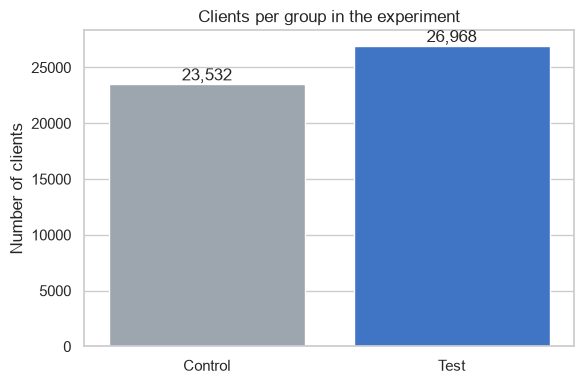

In [17]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=exp, x="variation", order=["Control", "Test"], ax=ax,
              hue="variation", palette={"Control": "#9aa5b1", "Test": "#2a6fdb"}, legend=False)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Clients per group in the experiment")
ax.set_xlabel("")
ax.set_ylabel("Number of clients")
plt.tight_layout()
plt.savefig(FIG_DIR / "experiment_group_sizes.png", dpi=150)
plt.show()

### Is the split 50/50? (chi-square goodness-of-fit test)
- **H0:** clients were split equally between Test and Control (50 / 50)
- **H1:** the split is not 50 / 50
- α = 0.05

In [18]:
observed = group_counts[["Control", "Test"]].values
expected = [observed.sum() / 2] * 2
chi2, p_value = stats.chisquare(observed, f_exp=expected)
print(f"Chi-square = {chi2:.2f},  p-value = {p_value:.3g}")
print("Reject H0 -> the split is NOT 50/50" if p_value < 0.05 else "Fail to reject H0 -> split is consistent with 50/50")

Chi-square = 233.78,  p-value = 8.92e-53
Reject H0 -> the split is NOT 50/50


**Note for the Experiment Evaluation (Lervin's card):** with ~50,000 clients, even a small imbalance is statistically significant. The Test group is a bit bigger than Control (about 53 % vs 47 %). This doesn't make the test invalid, but we should mention it, and we should compare **rates** (not counts) between groups. Later we should also check that the groups have similar demographics (age, tenure, gender).

## 10. Cross-check with the other datasets
This checks that the roster can be merged with Client Profiles and Digital Footprints. Both are only loaded to compare the `client_id`s. Their full cleaning is done in *Data cleaning 1* and *2*.

In [19]:
demo_ids = set(pd.read_csv(DATA_URL + "df_final_demo.txt", usecols=["client_id"])["client_id"])
web_ids = set(pd.concat([
    pd.read_csv(DATA_URL + "df_final_web_data_pt_1.txt", usecols=["client_id"]),
    pd.read_csv(DATA_URL + "df_final_web_data_pt_2.txt", usecols=["client_id"]),
])["client_id"])

exp_ids = set(exp["client_id"])
print(f"Experiment clients                     : {len(exp_ids):,}")
print(f"  ...found in Client Profiles (demo)   : {len(exp_ids & demo_ids):,}")
print(f"  ...found in Digital Footprints (web) : {len(exp_ids & web_ids):,}")
print(f"  ...with NO web activity              : {len(exp_ids - web_ids):,}")

Experiment clients                     : 50,500
  ...found in Client Profiles (demo)   : 50,500
  ...found in Digital Footprints (web) : 50,500
  ...with NO web activity              : 0


## 11. Apply the reusable cleaning function and save
All the steps above are collected in `clean_experiment_clients()` in `src/cleaning.py`, so the team can reuse them (for example in the merge notebook). Here we check that the function gives the same result as the step-by-step cleaning.

In [20]:
experiment_clean = clean_experiment_clients(df_raw)

# sanity checks
assert experiment_clean["client_id"].is_unique
assert experiment_clean["variation"].notna().all()
assert set(experiment_clean["variation"].unique()) <= {"Control", "Test"}
assert len(experiment_clean) == len(exp), "function and step-by-step results differ"

print(experiment_clean.shape)
experiment_clean.info()
experiment_clean.head()

(50500, 2)
<class 'pandas.DataFrame'>
RangeIndex: 50500 entries, 0 to 50499
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   client_id  50500 non-null  int64   
 1   variation  50500 non-null  category
dtypes: category(1), int64(1)
memory usage: 444.0 KB


,client_id,variation
0,555,Test
1,647,Test
2,934,Test
3,1028,Control
4,1104,Control


In [21]:
# 1) roster for the A/B analysis (Test + Control only)
experiment_clean.to_csv(CLEAN_DIR / "experiment_clients_clean.csv", index=False)

# 2) full roster with a flag (for EDA: experiment vs not-in-experiment clients)
roster_flagged = (df[["client_id", "variation", "in_experiment"]]
                  .assign(variation=lambda d: d["variation"].fillna("Not in experiment")))
roster_flagged.to_csv(CLEAN_DIR / "experiment_roster_all_flagged.csv", index=False)

print("Saved:")
print(" -", CLEAN_DIR / "experiment_clients_clean.csv")
print(" -", CLEAN_DIR / "experiment_roster_all_flagged.csv")

Saved:
 - c:\Users\julia\OneDrive\Documentos\GitHub\vanguard-ab-test\data\clean\experiment_clients_clean.csv
 - c:\Users\julia\OneDrive\Documentos\GitHub\vanguard-ab-test\data\clean\experiment_roster_all_flagged.csv


## 12. Summary of cleaning decisions

| Check | Finding | Action |
|---|---|---|
| Rows / columns | 70,609 rows · 2 columns (`client_id`, `Variation`) | – |
| Column names | `Variation` capitalised (not like the other datasets) | Renamed to `variation` |
| Duplicates | 0 duplicated rows · 0 duplicated `client_id` | None needed (still in the function as a safeguard) |
| `client_id` | All positive integers, no missing | Kept as `int64` |
| `variation` labels | Only `Test` and `Control`, no typos or extra spaces | Stripped + Title case as a safeguard; stored as `category` |
| Missing `variation` | 20,109 clients (28.5 %) stored as `NA` = **not in the experiment** | Removed from the A/B roster; kept with a flag in a second file |
| Client in both groups | 0 | – |
| Final A/B roster | **50,500 clients: Test 26,968 (53.4 %) · Control 23,532 (46.6 %)** | Saved to `data/clean/experiment_clients_clean.csv` |
| Group balance | Split is not exactly 50/50 (chi-square p < 0.05) | Flagged for the Experiment Evaluation; compare rates, not counts |
| Merge readiness | All roster clients exist in Client Profiles | Ready to merge on `client_id` |

*Numbers were checked against the source file on 12 Oct 2026. Re-run the notebook to confirm them.*

**Next step:** Merge this file with `demo_clean` and `web_data_clean` on `client_id`.